In [2]:
import os
import sys

# to setup import paths add project root dirs to sys.path
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from baseVR.base_functionality import init_import_paths
init_import_paths()


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# %matplotlib qt
# %matplotlib widget

from analytics_processing import analytics
import analytics_processing.analytics_constants as C
from CustomLogger import CustomLogger as Logger

from dashsrc.plot_components.plot_wrappers.data_selection import group_filter_data

from analytics_processing.modality_loading import session_modality_from_nas
from analytics_processing.sessions_from_nas_parsing import sessionlist_fullfnames_from_args
from analytics_processing.sessions_from_nas_parsing import fullfnames2snames


In [4]:
%matplotlib widget

In [5]:
output_dir = "/mnt/SpatialSequenceLearning/Simon/kinematics_errors"
data = {}
nas_dir = C.device_paths()[0]
Logger().init_logger(None, None, logging_level="INFO")


In [51]:
animal_ids = [6]
paradigm_ids = [1100]
session_ids = None

In [52]:
session_dirs = sessionlist_fullfnames_from_args(paradigm_ids, animal_ids, session_ids)[0]
session_names = fullfnames2snames(session_dirs)

In [53]:
framew_beh = analytics.get_analytics('BehaviorFramewise', session_names=session_names)#[:34],)
# framew_beh = analytics.get_analytics('BehaviorTrackwise', session_names=session_names)#[:34],)
framew_beh

/home/vrmaster/Projects/VirtualReality/analysisVR/analytics_processing/analytics.py:660: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  aggr = pd.concat(aggr)
2026-04-02 09:12:21,822|INFO|452014|analytics|get_analytics
	Returning BehaviorFramewise for 34 sessions.


frame_id  frame_pc_timestamp  \
paradigm_id animal_id session_id       entry_id                                 
1100        6         2024-11-14_15-01 0            14109    1731592882746345   
                                       1            14110    1731592882763007   
                                       2            14111    1731592882779674   
                                       3            14112    1731592882797859   
                                       4            14113    1731592882814538   
...                                                   ...                 ...   
                      2025-01-27_13-39 265636      287569    1737986032936566   
                                       265637      287570    1737986032953237   
                                       265638      287571    1737986032969901   
                                       265639      287572    1737986032986570   
                                       265640      287573    1737986033003237   

                                                 frame_position  \
paradigm_id animal_id session_id       entry_id                   
1100        6         2024-11-14_15-01 0                    NaN   
                                       1                    NaN   
                                       2                    NaN   
                                       3                    NaN   
                                       4                    NaN   
...                                                         ...   
                      2025-01-27_13-39 265636         -166.7919   
                                       265637         -166.7178   
                                       265638         -166.6485   
                                       265639         -166.5945   
                                       265640         -166.5251   

                                                 frame_ephys_timestamp  \
paradigm_id animal_id session_id       entry_id                          
1100        6         2024-11-14_15-01 0                           NaN   
                                       1                           NaN   
                                       2                           NaN   
                                       3                           NaN   
                                       4                           NaN   
...                                                                ...   
                      2025-01-27_13-39 265636             4.435022e+09   
                                       265637             4.435039e+09   
                                       265638             4.435056e+09   
                                       265639             4.435072e+09   
                                       265640             4.435089e+09   

                                                 trial_id frame_ephys_patched  \
paradigm_id animal_id session_id       entry_id                                 
1100        6         2024-11-14_15-01 0              NaN                None   
                                       1              NaN                None   
                                       2              NaN                None   
                                       3              NaN                None   
                                       4              NaN                None   
...                                                   ...                 ...   
                      2025-01-27_13-39 265636       152.0                   0   
                                       265637       152.0                   0   
                                       265638       152.0                   0   
                                       265639       152.0                   0   
                                       265640       152.0                   0   

                                                       fps track_zone  \
paradigm_id animal_id session_id 

In [68]:
action_cols = [
               # forward velocity and acc
               'frame_raw', 
               'frame_raw_500msMedian', 
               'frame_yaw', 
               'frame_pitch', 
               'frame_raw_abs_acc_500msMedian', 
               # off rotations velocity
               'frame_YawPitch_abs_vel_sum_500msMedian', 
               'frame_YawPitch_abs_acc_sum_500msMedian', 
               # sum for reward threshold and acc
               'frame_RawYawPitch_abs_vel_sum',
               'frame_RawYawPitch_abs_vel_sum_500msMedian',
               'frame_RawYawPitch_abs_acc_sum_500msMedian',
               # others
               'lick_detected', 
               'trial_id', 
               'cue', 
               'trial_outcome', 
               'choice_R1', 
               'choice_R2', 
               # derived metrics
               'frame_forward_prop',
               'velocity_threshold_at_R1',
               'forward_vs_rotation_corr',
               
               'frame_below_velocity_thr',
            #    'reward-sound_count'
               ]

# renamer = {
#       'frame_raw_500msMedian': 'ball_forward_vel',
#       'frame_raw_abs_acc_500msMedian': 'ball_forward_acc',
#       'frame_YawPitch_abs_vel_sum_500msMedian': 'ball_rotation_vel',
#       'frame_YawPitch_abs_acc_sum_500msMedian': 'ball_rotation_acc',
#       'frame_RawYawPitch_abs_vel_sum': 'ball_forward+rotation_vel',
#       # 'frame_RawYawPitch_abs_vel_sum_500msMedian': 'ball_forward+rotation_vel',
#       'frame_RawYawPitch_abs_acc_sum_500msMedian': 'ball_forward+rotation_acc',
#       'lick_detected': 'licking',
#       'frame_forward_prop': 'forward_proportion',
#       'forward_vs_rotation_corr': 'forward_vs_rotation_corr',
#       'frame_below_velocity_thr': 'below_r_thr',
# }
framew_beh['frame_below_velocity_thr'] = framew_beh['frame_below_velocity_thr'].fillna(0)
actions = framew_beh[action_cols].dropna() # # just for NaN dropping (first ~80 frames of a session)
actions = actions#.rename(columns=renamer)

actions

frame_raw  \
paradigm_id animal_id session_id       entry_id              
1100        6         2024-11-14_15-01 88        14.899892   
                                       89        20.620413   
                                       90        24.251396   
                                       91        27.930426   
                                       92        30.082838   
...                                                    ...   
                      2025-01-27_13-39 265636     5.276067   
                                       265637     4.439806   
                                       265638     4.164066   
                                       265639     3.237747   
                                       265640     4.163317   

                                                 frame_raw_500msMedian  \
paradigm_id animal_id session_id       entry_id                          
1100        6         2024-11-14_15-01 88                    21.552511   
                                       89                    21.552511   
                                       90                    22.435904   
                                       91                    24.799924   
                                       92                    25.488759   
...                                                                ...   
                      2025-01-27_13-39 265636                 5.321221   
                                       265637                 5.366375   
                                       265638                 5.688945   
                                       265639                 6.011516   
                                       265640                 6.013681   

                                                 frame_yaw  frame_pitch  \
paradigm_id animal_id session_id       entry_id                           
1100        6         2024-11-14_15-01 88         1.141520    -3.193374   
                                       89         1.596786    -3.899736   
                                       90         0.837265    -3.903716   
                                       91         0.152102    -3.191267   
                                       92         0.304460    -3.903716   
...                                                    ...          ...   
                      2025-01-27_13-39 265636     5.936971     0.000000   
                                       265637     6.617240     0.000000   
                                       265638     7.685310     0.000000   
                                       265639     7.302658     0.000000   
                                       265640     9.053339     0.000000   

                                                 frame_raw_abs_acc_500msMedian  \
paradigm_id animal_id session_id       entry_id                                  
1100        6         2024-11-14_15-01 88                        -1.136868e-13   
                                       89                         2.652743e+01   
                                       90                         9.738852e+01   
                                       91                         9.154655e+01   
                                       92                         2.068059e+01   
...                                                                        ...   
                      2025-01-27_13-39 265636                     2.709505e+00   
                                       265637                     1.103464e+01   
                                       265638                     1.935439e+01   
                                       265639                     9.740134e+00   
                                       265640                     1.298893e-01   

                                                 frame_YawPitch_abs_vel_sum_500msMedian  \
paradigm_id animal_id session_id       entry_id                                           
1100        6         2024-11-14_15-01 88             

In [66]:
actions_cp = actions.copy()
actions_cp['track_zone'] = framew_beh.loc[actions.index, 'track_zone']
actions_cp['trial_id'] = framew_beh.loc[actions.index, 'trial_id']
actions_cp.reset_index(inplace=True)

nframes_pre = 60
def around_r1_entries(group):
    # whole trial
    upcoming_choice = np.zeros(group.shape[0])
    r1_entry = group[group['track_zone'] == 'reward1Zone'].index[0]
    pre_r1_mask = (group.index >= r1_entry - nframes_pre) & (group.index < r1_entry)
    upcoming_choice[pre_r1_mask] = -1 if group['choice_R1'].iloc[0] == 0 else 1
    
    r2_entry = group[group['track_zone'] == 'reward2Zone'].index[0]
    pre_r2_mask = (group.index >= r2_entry - nframes_pre) & (group.index < r2_entry)
    upcoming_choice[pre_r2_mask] = -1 if group['choice_R2'].iloc[0] == 0 else 1
    
def around_r2_entries(group):
    r2_idx = group[group['track_zone'] == 'reward2Zone'].index[0]
    return np.arange(r2_idx - nframes_pre, r2_idx)

r1_entries = actions_cp.groupby(by=['session_id', 'trial_id']).apply(around_r1_entries, )
# r2_entries = actions_cp.groupby(by=['session_id', 'trial_id']).apply(around_r2_entries, )

# r1_entries = np.concatenate(r1_entries.values)
# print(r1_entries.shape)
# # print(frame_id_from_start.shape)
# print(f"Slicing to {nframes_pre} frames before and {nframes_post} frames after R1 entry gives us {len(r1_entries)}/{len(actions_cp)} frames to analyze around R1 entries.")

# actions = actions.iloc[r1_entries]
# actions['frame_id_from_start'] = actions.groupby(by=['session_id', 'trial_id']).cumcount()

/tmp/ipykernel_452014/486620984.py:22: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  r1_entries = actions_cp.groupby(by=['session_id', 'trial_id']).apply(around_r1_entries, )


In [69]:
actions_cp = actions.copy()
actions_cp['track_zone'] = framew_beh.loc[actions.index, 'track_zone']
actions_cp['trial_id'] = framew_beh.loc[actions.index, 'trial_id']
actions_cp.reset_index(inplace=True)
actions_cp

nframes_pre, nframes_post = 65, 125
def around_r1_entries(group):
    r1_idx = group[group['track_zone'] == 'reward2Zone'].index[0]
    # first_r_idx = group[group['reward-sound_count'] == 1].index
    return np.arange(r1_idx - nframes_pre, r1_idx + nframes_post)
    # r1_idx = group[group['track_zone'] == 'reward1Zone'].index
    # return np.arange(r1_idx[0]-60, r1_idx[-1]+30)

r1_entries = actions_cp.groupby(by=['session_id', 'trial_id']).apply(around_r1_entries, )

r1_entries = np.concatenate(r1_entries.values)
print(r1_entries.shape)
# print(frame_id_from_start.shape)
print(f"Slicing to {nframes_pre} frames before and {nframes_post} frames after R1 entry gives us {len(r1_entries)}/{len(actions_cp)} frames to analyze around R1 entries.")

actions = actions.iloc[r1_entries]
actions['frame_id_from_start'] = actions.groupby(by=['session_id', 'trial_id']).cumcount()

(690460,)
Slicing to 65 frames before and 125 frames after R1 entry gives us 690460/4087656 frames to analyze around R1 entries.


/tmp/ipykernel_452014/3463057378.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  r1_entries = actions_cp.groupby(by=['session_id', 'trial_id']).apply(around_r1_entries, )
/tmp/ipykernel_452014/3463057378.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  actions['frame_id_from_start'] = actions.groupby(by=['session_id', 'trial_id']).cumcount()


In [70]:
actions

frame_raw  \
paradigm_id animal_id session_id       entry_id              
1100        6         2024-11-14_15-01 467       55.230022   
                                       468       54.797047   
                                       469       51.803947   
                                       470       49.222609   
                                       471       47.548623   
...                                                    ...   
                      2025-01-27_13-39 263540    28.949496   
                                       263541    32.668707   
                                       263542    36.000360   
                                       263543    37.183372   
                                       263544    40.428006   

                                                 frame_raw_500msMedian  \
paradigm_id animal_id session_id       entry_id                          
1100        6         2024-11-14_15-01 467                   52.627046   
                                       468                   53.100571   
                                       469                   53.652488   
                                       470                   54.273433   
                                       471                   54.273433   
...                                                                ...   
                      2025-01-27_13-39 263540                30.809102   
                                       263541                34.334534   
                                       263542                36.591866   
                                       263543                37.797268   
                                       263544                38.583484   

                                                 frame_yaw  frame_pitch  \
paradigm_id animal_id session_id       entry_id                           
1100        6         2024-11-14_15-01 467        8.824574   -10.286057   
                                       468       10.503872   -10.202893   
                                       469        9.736877    -9.132761   
                                       470       11.336373    -8.690988   
                                       471       11.334333    -8.334753   
...                                                    ...          ...   
                      2025-01-27_13-39 263540    -3.954894    -1.418426   
                                       263541    -4.109471     0.000000   
                                       263542    -3.424559     0.088705   
                                       263543    -3.498770     0.531942   
                                       263544    -3.803696     0.266019   

                                                 frame_raw_abs_acc_500msMedian  \
paradigm_id animal_id session_id       entry_id                                  
1100        6         2024-11-14_15-01 467                           26.842191   
                                       468                           30.766713   
                                       469                           35.184535   
                                       470                           18.630914   
                                       471                            0.000000   
...                                                                        ...   
                      2025-01-27_13-39 263540                       174.107410   
                                       263541                       173.532052   
                                       263542                       103.899602   
                                       263543                        59.736426   
                                       263544                        34.409204   

                                                 frame_YawPitch_abs_vel_sum_500msMedian  \
paradigm_id animal_id session_id       entry_id                                           
1100        6         2024-11-14_15-01 467            

In [71]:
actions = actions.set_index(['trial_id', 'frame_id_from_start'], append=True).reset_index(level=[0,1,3])
actions

paradigm_id  animal_id  \
session_id       trial_id frame_id_from_start                           
2024-11-14_15-01 1.0      0                           1100          6   
                          1                           1100          6   
                          2                           1100          6   
                          3                           1100          6   
                          4                           1100          6   
...                                                    ...        ...   
2025-01-27_13-39 152.0    185                         1100          6   
                          186                         1100          6   
                          187                         1100          6   
                          188                         1100          6   
                          189                         1100          6   

                                               entry_id  frame_raw  \
session_id       trial_id frame_id_from_start                        
2024-11-14_15-01 1.0      0                         467  55.230022   
                          1                         468  54.797047   
                          2                         469  51.803947   
                          3                         470  49.222609   
                          4                         471  47.548623   
...                                                 ...        ...   
2025-01-27_13-39 152.0    185                    263540  28.949496   
                          186                    263541  32.668707   
                          187                    263542  36.000360   
                          188                    263543  37.183372   
                          189                    263544  40.428006   

                                               frame_raw_500msMedian  \
session_id       trial_id frame_id_from_start                          
2024-11-14_15-01 1.0      0                                52.627046   
                          1                                53.100571   
                          2                                53.652488   
                          3                                54.273433   
                          4                                54.273433   
...                                                              ...   
2025-01-27_13-39 152.0    185                              30.809102   
                          186                              34.334534   
                          187                              36.591866   
                          188                              37.797268   
                          189                              38.583484   

                                               frame_yaw  frame_pitch  \
session_id       trial_id frame_id_from_start                           
2024-11-14_15-01 1.0      0                     8.824574   -10.286057   
                          1                    10.503872   -10.202893   
                          2                     9.736877    -9.132761   
                          3                    11.336373    -8.690988   
                          4                    11.334333    -8.334753   
...                                                  ...          ...   
2025-01-27_13-39 152.0    185                  -3.954894    -1.418426   
                          186                  -4.109471     0.000000   
                          187                  -3.424559     0.088705   
                          188                  -3.498770     0.531942   
                          189                  -3.803696     0.266019   

                                               frame_raw_abs_acc_500msMedian  \
session_id       trial_id frame_id_from_start                                  
2024-11-14_15-01 1.0      0                                        26.842191   
                          1                                

In [72]:

# saVE
# final_labels.to_csv(os.path.join(output_dir, "trial_cluster_labels.csv"), index=False)
# print(f"✓ Saved trial cluster labels to {output_dir}/trial_cluster_labels.csv")

hmm_labels = pd.read_csv(os.path.join(output_dir, "trial_cluster_labels.csv"))
hmm_labels = hmm_labels.set_index(['trial_id', 'session_id'], drop=True)
hmm_labels

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/SpatialSequenceLearning/Simon/kinematics_errors/trial_cluster_labels.csv'

In [73]:
plt.close("all")

def plot_all_sessions_vel_props_fast(
    all_data,
    hmm_labels_df,
    target_cluster=3,
    y_col="frame_raw_500msMedian",
    color_col="frame_forward_prop",
    cmap="RdBu_r",
    color_vmin=0.3,
    color_vmax=0.7,
    x_lim=(0, 180),
    y_lim=(0, 150),
):
    # --- Validate inputs ---
    if "cluster_k_id" not in hmm_labels_df.columns:
        raise ValueError("hmm_labels_df must contain 'cluster_k_id' column.")
    if not {"trial_id", "session_id"}.issubset(set(hmm_labels_df.index.names)):
        raise ValueError("hmm_labels_df index must include 'trial_id' and 'session_id'.")
    if y_col not in all_data.columns:
        raise ValueError(f"'{y_col}' not found in all_data columns.")
    if color_col not in all_data.columns:
        raise ValueError(f"'{color_col}' not found in all_data columns.")

    wanted = hmm_labels_df[hmm_labels_df["cluster_k_id"] == target_cluster]
    if wanted.empty:
        print(f"No trials found for cluster {target_cluster}.")
        return

    wanted_pairs = pd.MultiIndex.from_arrays(
        [
            wanted.index.get_level_values("session_id"),
            wanted.index.get_level_values("trial_id"),
        ],
        names=["session_id", "trial_id"],
    ).unique()

    pair_index_all = pd.MultiIndex.from_arrays(
        [
            all_data.index.get_level_values("session_id"),
            all_data.index.get_level_values("trial_id"),
        ],
        names=["session_id", "trial_id"],
    )
    keep_mask = pair_index_all.isin(wanted_pairs)
    data_sub = all_data[keep_mask]

    if data_sub.empty:
        print("No overlap between selected cluster trials and all_data index.")
        return

    if color_vmin is None or color_vmax is None:
        q = data_sub[color_col].quantile([0.05, 0.95]).values
        if color_vmin is None:
            color_vmin = float(q[0])
        if color_vmax is None:
            color_vmax = float(q[1])

    fig = plt.figure(figsize=(10, 4))
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.3)
    ax0 = fig.add_subplot(gs[0, 0])
    ax1 = fig.add_subplot(gs[0, 1], sharey=ax0)
    ax = [ax0, ax1]
    cax = fig.add_subplot(gs[0, 2])

    stop_y, stop_c = [], []
    skip_y, skip_c = [], []
    total_trials = 0
    n_stop = 0
    labeled = False

    grouped = data_sub.groupby(level=["session_id", "trial_id"], sort=False)
    
    if y_lim is None:
        # 99th percentile of y_col across all selected trials for dynamic y-axis scaling
        y_lim_upper = data_sub[y_col].quantile(0.99)
        ylim_lower = data_sub[y_col].quantile(0.01)
        y_lim = (ylim_lower, y_lim_upper)

    for (_, _), trial_data in grouped:
        trial_data = trial_data.reset_index(drop=True)
        if trial_data.empty:
            continue

        y_vals = trial_data[y_col].to_numpy()
        c_vals = trial_data[color_col].to_numpy()
        if np.all(np.isnan(y_vals)) or np.all(np.isnan(c_vals)):
            continue

        total_trials += 1
        is_stop = trial_data.iloc[0]["choice_R1"] > 0
        ax_i = 1 if is_stop else 0
        x = np.arange(len(trial_data))

        if is_stop:
            n_stop += 1
            stop_y.append(y_vals)
            stop_c.append(c_vals)
        else:
            skip_y.append(y_vals)
            skip_c.append(c_vals)

        ax[ax_i].scatter(
            x, y_vals, c=c_vals,
            alpha=0.12, s=6, cmap=cmap,
            vmin=color_vmin, vmax=color_vmax, linewidths=0
        )

        if is_stop and "frame_below_velocity_thr" in trial_data.columns:
            r_time = trial_data.loc[
                trial_data["frame_below_velocity_thr"].astype(bool), y_col
            ].iloc[0:1]
            if not r_time.empty:
                ax[ax_i].scatter(
                    r_time.index, r_time.values,
                    marker="|", s=120, color="k",
                    label="below reward thresh." if not labeled else None
                )
                labeled = True

    if total_trials == 0:
        plt.close(fig)
        print("No trials to plot after filtering.")
        return

    def mean_trace(arr_list):
        min_len = min(len(a) for a in arr_list)
        arr = np.vstack([a[:min_len] for a in arr_list])
        return np.nanmean(arr, axis=0), min_len

    sc_for_cbar = None
    if stop_y:
        stop_y_m, stop_len = mean_trace(stop_y)
        stop_c_m, _ = mean_trace(stop_c)
        sc_for_cbar = ax[1].scatter(
            np.arange(stop_len), stop_y_m,
            c=stop_c_m, s=30, cmap=cmap,
            vmin=color_vmin, vmax=color_vmax
        )

    if skip_y:
        skip_y_m, skip_len = mean_trace(skip_y)
        skip_c_m, _ = mean_trace(skip_c)
        sc_for_cbar = ax[0].scatter(
            np.arange(skip_len), skip_y_m,
            c=skip_c_m, s=30, cmap=cmap,
            vmin=color_vmin, vmax=color_vmax
        )

    xtick_frames = np.array([0, 60, 120])
    xtick_times = xtick_frames - 60
    y_label = y_col.replace("_", " ")

    for axis in ax:
        axis.set_xlim(*x_lim)
        if y_lim is not None:
            axis.set_ylim(*y_lim)
        axis.grid(True, axis="y", alpha=0.3)
        axis.set_xticks(xtick_frames)
        axis.set_xticklabels([f"{t/60:.1f}" for t in xtick_times])
        axis.set_ylabel(y_label)
        axis.axvline(60, color="k", linestyle="--", linewidth=1, alpha=0.6)
        axis.text(
            60, axis.get_ylim()[1] * 0.93, "reward zone entry",
            fontsize=9, ha="center",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
        )
        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)

    frac_stop = 100.0 * n_stop / total_trials
    frac_skip = 100.0 - frac_stop
    # ax[0].set_title(f"Skip trials ({frac_skip:.0f}%)", pad=8)
    # ax[1].set_title(f"Stop trials ({frac_stop:.0f}%)", pad=8)
    ax[0].set_xlabel(f"[s], skipped ({frac_skip:.0f}%)")
    ax[1].set_xlabel(f"[s], stopped ({frac_stop:.0f}%)")
    ax[1].legend(loc="best", fontsize=8)

    if sc_for_cbar is not None:
        cbar = fig.colorbar(sc_for_cbar, cax=cax)
        cbar.set_label(color_col.replace("_", " "), rotation=270, labelpad=15)

    fig.suptitle(
        f"All sessions (cluster {target_cluster}, n={total_trials} trials)\n"
        f"y={y_col}, color={color_col}",
        y=0.98, fontsize=11
    )
    fig.tight_layout(rect=[0, 0.02, 1, 0.88])  # reserve top space for suptitle
    plt.show()

In [74]:
# # Overview iterator: plot every requested y-metric for every cluster
# # Always colors by frame_forward_prop (with fallback to forward_proportion).

# from IPython.display import display, Markdown
# import numpy as np

# # 1) Metrics to iterate (from your list)
# metrics_to_plot = [
#     "frame_raw",
#     "frame_raw_500msMedian",
#     # "frame_yaw",
#     # "frame_pitch",
#     "frame_raw_abs_acc_500msMedian",
#     "frame_RawYawPitch_abs_vel_sum_500msMedian",
#     "frame_YawPitch_abs_vel_sum_500msMedian",
#     "frame_YawPitch_abs_acc_sum_500msMedian",
#     "frame_RawYawPitch_abs_vel_sum",
#     # "trial_id",
#     # "trial_outcome",
#     # "choice_R1",
#     "frame_forward_prop",
#     # "velocity_threshold_at_R1",
#     "forward_vs_rotation_corr",
#     # "frame_below_velocity_thr",
# ]

# # 2) Force color column (your request)
# if "frame_forward_prop" in actions.columns:
#     fixed_color_col = "frame_forward_prop"
# elif "forward_proportion" in actions.columns:
#     fixed_color_col = "forward_proportion"  # fallback if you renamed columns
# else:
#     raise ValueError("Neither 'frame_forward_prop' nor 'forward_proportion' exists in actions.")

# def plot_overview_all_clusters(
#     all_data,
#     hmm_labels_df,
#     metrics,
#     color_col,
#     clusters=None,
#     x_lim=(0, 180),
#     y_lim=None,            # None = auto-scale per plot
#     color_vmin=None,       # None = auto from data quantiles in your function
#     color_vmax=None,
# ):
#     if "cluster_k_id" not in hmm_labels_df.columns:
#         raise ValueError("hmm_labels_df must contain 'cluster_k_id'.")

#     # Choose clusters
#     if clusters is None:
#         clusters = (
#             hmm_labels_df["cluster_k_id"]
#             .dropna()
#             .astype(int)
#             .sort_values()
#             .unique()
#             .tolist()
#         )

#     # Keep only metrics that exist
#     valid_metrics = [m for m in metrics if m in all_data.columns]
#     missing_metrics = [m for m in metrics if m not in all_data.columns]

#     if missing_metrics:
#         print("Skipping missing metrics:")
#         for m in missing_metrics:
#             print(f"  - {m}")

#     if not valid_metrics:
#         raise ValueError("No valid metrics found in all_data.")

#     display(Markdown(f"# All Clusters Overview\nColor metric fixed to: `{color_col}`"))

#     for cluster_id in clusters:
#         if cluster_id == 0:
#             continue  # skip cluster 0 if you want, or remove this condition to include it
#         display(Markdown(f"---\n## Cluster {cluster_id}"))
#         for y_col in valid_metrics:
#             display(Markdown(f"### y: `{y_col}`  |  color: `{color_col}`"))
#             plot_all_sessions_vel_props_fast(
#                 all_data=all_data,
#                 hmm_labels_df=hmm_labels_df,
#                 target_cluster=int(cluster_id),
#                 y_col=y_col,
#                 color_col=color_col,
#                 cmap="RdBu_r",
#                 color_vmin=color_vmin,
#                 color_vmax=color_vmax,
#                 x_lim=x_lim,
#                 y_lim=y_lim,
#             )
#         # break

# # 3) Run
# plot_overview_all_clusters(
#     all_data=actions,
#     hmm_labels_df=hmm_labels,
#     metrics=metrics_to_plot,
#     color_col=fixed_color_col,
#     clusters=None,      # or e.g. [0,1,2,3,4]
#     x_lim=(0, 180),
#     y_lim=None,         # use None for per-metric auto y-range
#     color_vmin=None,    # use None for automatic color limits
#     color_vmax=None,
# )

In [75]:
actions.loc[actions['cue'] == 0] = 1
actions.cue.value_counts()

cue
1.0    347164
2.0    343296
Name: count, dtype: int64

/tmp/ipykernel_452014/1840460755.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.05, 1, 0.95])


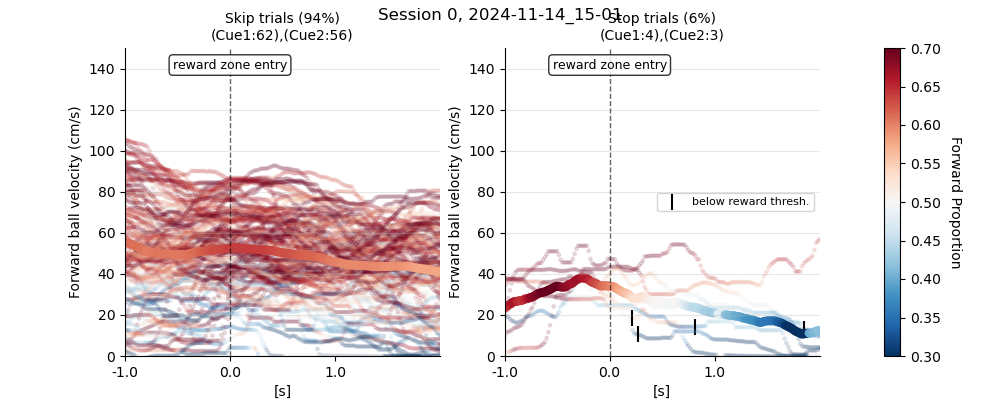

/tmp/ipykernel_452014/1840460755.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.05, 1, 0.95])


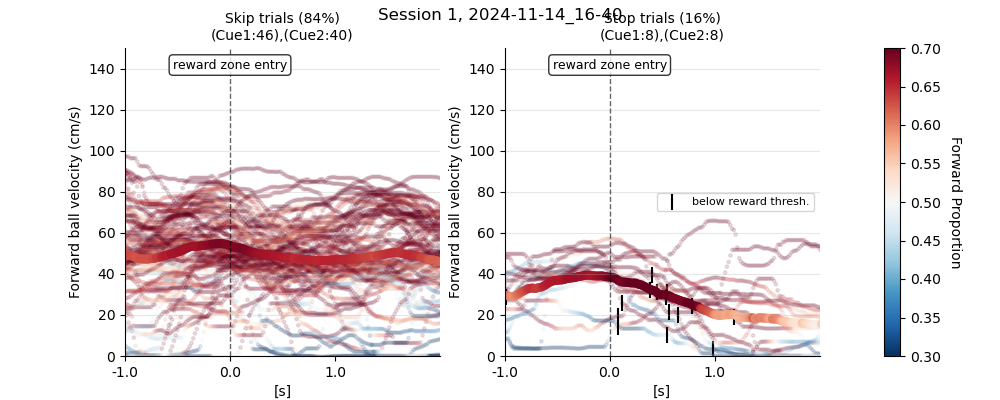

/tmp/ipykernel_452014/1840460755.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.05, 1, 0.95])


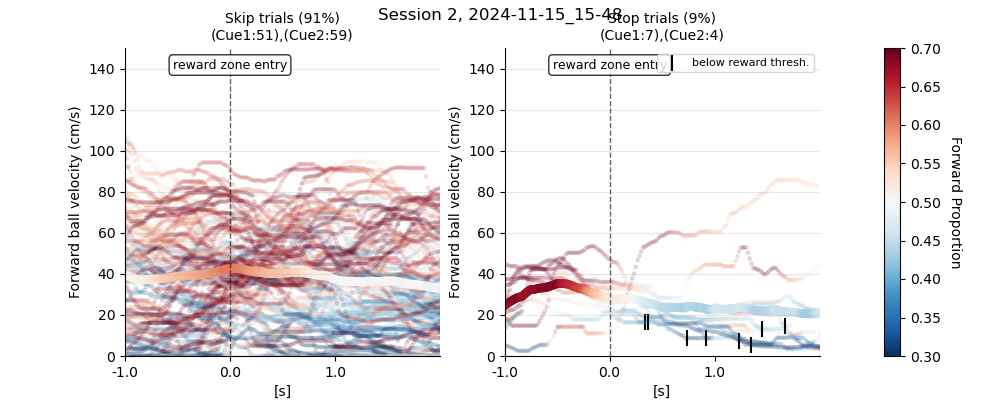

/tmp/ipykernel_452014/1840460755.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.05, 1, 0.95])


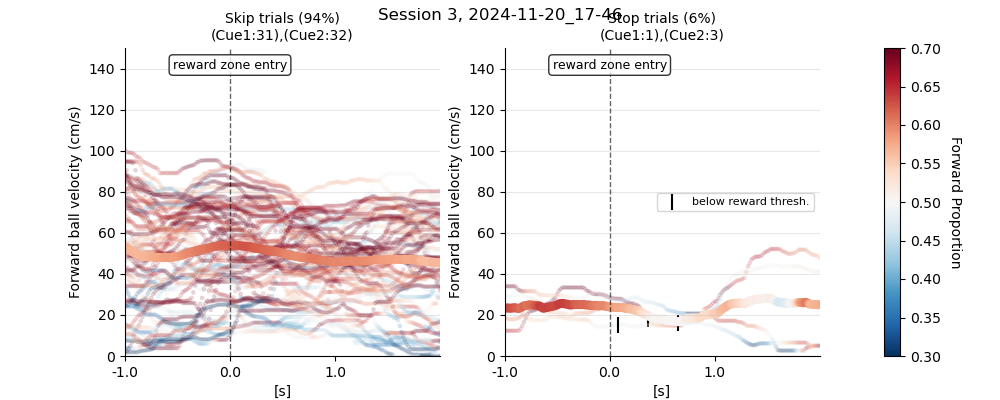

/tmp/ipykernel_452014/1840460755.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.05, 1, 0.95])


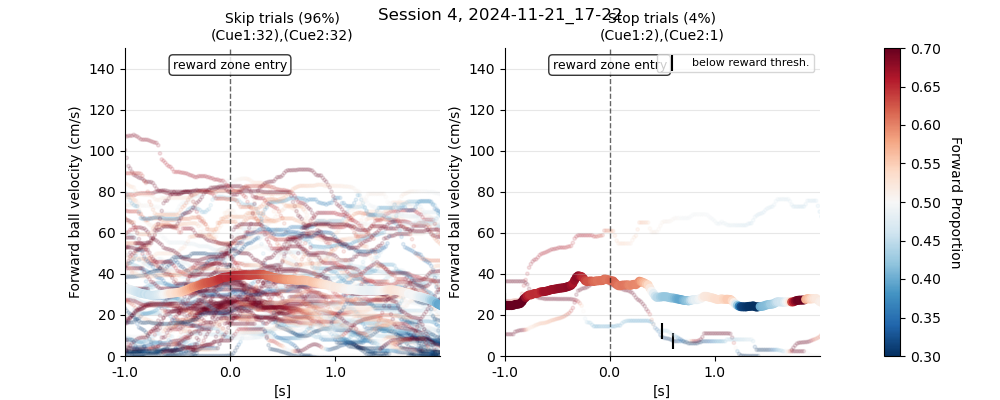

ValueError: all input arrays must have the same shape

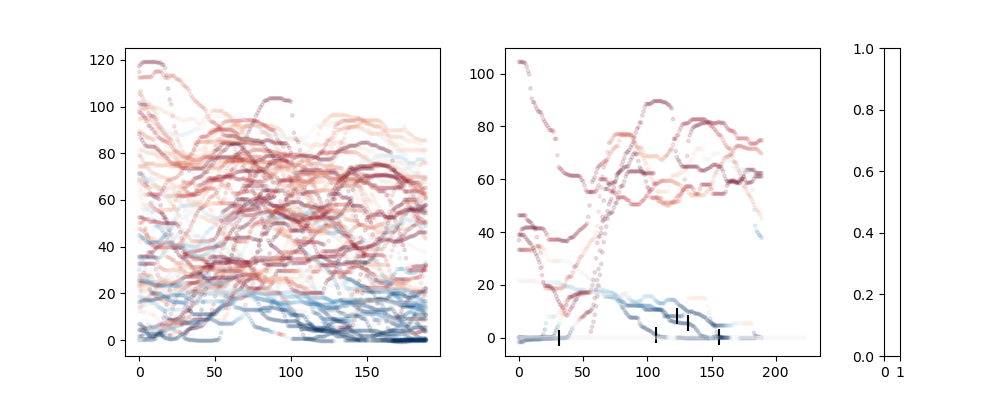

In [78]:
plt.close("all")
def plot_session_vel_props(session_data):
    fig = plt.figure(figsize=(10, 4))
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.3)
    ax = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])]
    cax = fig.add_subplot(gs[0, 2])
    
    n_choices = 0
    choicewise_cues = {'stopR1Cue1': 0, 'skipR1Cue1': 0, 'stopR1Cue2': 0, 'skipR1Cue2': 0}
    n = len(session_data.index.unique("trial_id"))
    
    stop_choices, stop_choice_c = [], []
    skip_choices, skip_choice_c = [], []
    
    sample_of_trials = session_data.index.unique("trial_id")
    
    labeled = False
    for trial_id in sample_of_trials:
        trial_mask = session_data.index.get_level_values('trial_id') == trial_id
        trial_data = session_data[trial_mask]
        trial_data = trial_data.reset_index(drop=True)
        
        ax_i = 1 if (trial_data.iloc[0]['choice_R1'] %5) >0 else 0
        
        x = np.arange(trial_data.shape[0])
        col = trial_data['frame_forward_prop'].values
        cue = str(int(trial_data.iloc[0]['cue']))
        
        # stop trials
        if ax_i:
            n_choices += ax_i
            stop_choices.append(trial_data['frame_raw_500msMedian'].values)
            stop_choice_c.append(col)
            # update cue counts for stop trials based on choice_R1 value
            choicewise_cues['stopR1Cue'+cue] += 1
        # skip trials
        else:
            skip_choices.append(trial_data['frame_raw_500msMedian'].values)
            skip_choice_c.append(col)
            choicewise_cues['skipR1Cue'+cue] += 1
        
        sc = ax[ax_i].scatter(x, trial_data['frame_raw_500msMedian'].values, c=col, alpha=0.12, s=6, cmap='RdBu_r', vmin=.3, vmax=.7)
        
        if ax_i == 1:
            r_time = trial_data.loc[trial_data['frame_below_velocity_thr'].astype(bool), 'frame_raw_500msMedian'].iloc[0:1]
            ax[ax_i].scatter(r_time.index, r_time.values, marker='|', s=120, color='k', label='below reward thresh.' if not labeled else None)
            labeled = True
    if len(stop_choices) == 0 or len(skip_choices) == 0:
        print("No stop or skip choices found in this session.")
        plt.close(fig)
        return

    stop_choices = np.stack(stop_choices).mean(0)
    stop_choice_c = np.stack(stop_choice_c).mean(0)
    ax[1].scatter(np.arange(len(stop_choices)), stop_choices, c=stop_choice_c, s=30, cmap='RdBu_r', vmin=.3, vmax=.7)
    
    skip_choices = np.stack(skip_choices).mean(0)
    skip_choice_c = np.stack(skip_choice_c).mean(0)
    sc = ax[0].scatter(np.arange(len(skip_choices)), skip_choices, c=skip_choice_c, s=30, cmap='RdBu_r', vmin=.3, vmax=.7)
    
    # Set xticks to reflect time from t=0 (frame 60 = t=0)
    xtick_frames = np.array([0,60,120])
    xtick_times = xtick_frames-60
    
    for i, axis in enumerate(ax):
        axis.set_xlim(0, 180)
        axis.set_ylim(0, 150)
        axis.grid(True, axis='y', alpha=0.3)
        axis.set_xticks(xtick_frames)
        axis.set_xticklabels([f'{t/60:.1f}' for t in xtick_times])
        axis.set_ylabel('Forward ball velocity (cm/s)')
        axis.axvline(60, color='k', linestyle='--', linewidth=1, alpha=0.6)
        axis.text(60, 140, 'reward zone entry', fontsize=9, ha='center', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        # Remove spines
        axis.spines['top'].set_visible(False)
        axis.spines['right'].set_visible(False)
    
    
    stop_cue_text = ",".join([f"({k.replace('stopR1', '')}:{v})" for k, v in choicewise_cues.items() if k.startswith('stop')])
    skip_cue_text = ",".join([f"({k.replace('skipR1', '')}:{v})" for k, v in choicewise_cues.items() if k.startswith('skip')])
    ax[0].set_title(f"Skip trials ({(n-n_choices)/n*100:.0f}%)\n{skip_cue_text}", fontsize=10)
    ax[0].set_xlabel("[s]")
    ax[1].set_xlabel("[s]")
    ax[1].set_title(f"Stop trials ({n_choices/n*100:.0f}%)\n{stop_cue_text}", fontsize=10)
    ax[1].legend(loc='best', fontsize=8)
    
    # Add colorbar on the dedicated axis
    cbar = plt.colorbar(sc, cax=cax)
    cbar.set_label('Forward Proportion', rotation=270, labelpad=15)
    
    # Add shared x-axis label
    # fig.text(0.5, 0.02, 'Time from R2 entry (frames)', ha='center', fontsize=10)

        
for i, s_id in enumerate(actions.index.unique('session_id')):
    session_data = actions.loc[s_id]
    plot_session_vel_props(session_data)
    plt.suptitle(f"Session {i}, {s_id}", y=0.98)
    plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.show()
    # break

In [ ]:
actions

In [ ]:
framew_beh

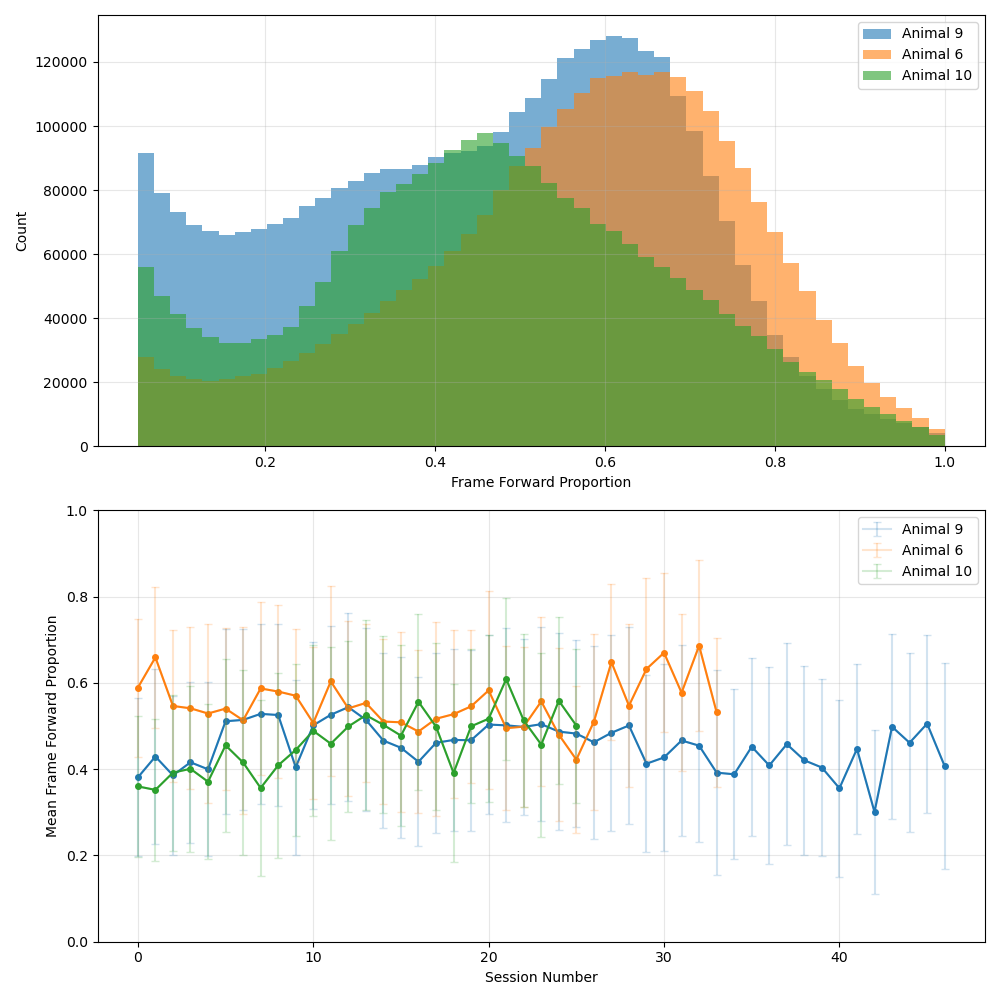

In [49]:
plt.close("all")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10))

# Top subplot: Histogram
for animal_id in framew_beh.index.get_level_values('animal_id').unique():
    animal_mask = framew_beh.index.get_level_values('animal_id') == animal_id
    # Use copy to avoid SettingWithCopyWarning
    values = framew_beh.loc[animal_mask, 'frame_forward_prop'].copy()
    values.loc[values == 0.5] = np.nan
    values.loc[values < 0.05] = np.nan
    
    ax1.hist(values.dropna(), bins=50, label=f"Animal {animal_id}", alpha=0.6)

ax1.set_xlabel("Frame Forward Proportion")
ax1.set_ylabel("Count")
ax1.grid(True, alpha=0.3)
ax1.legend()

# Bottom subplot: Line plot over sessions per animal
for animal_id in framew_beh.index.get_level_values('animal_id').unique():
    animal_mask = framew_beh.index.get_level_values('animal_id') == animal_id
    animal_data = framew_beh[animal_mask].copy()
    
    # Filter for the lineplot as well
    animal_data.loc[animal_data['frame_forward_prop'] == 0.5, 'frame_forward_prop'] = np.nan
    animal_data.loc[animal_data['frame_forward_prop'] < 0.05, 'frame_forward_prop'] = np.nan
    
    session_mean = animal_data['frame_forward_prop'].groupby(level='session_id').mean()
    session_std = animal_data['frame_forward_prop'].groupby(level='session_id').std()
    
    # Session number starting from 0
    x_vals = np.arange(len(session_mean))
    
    # Add alpha to errorbar parameters
    ax2.errorbar(x_vals, session_mean.values, yerr=session_std.values, label=f"Animal {animal_id}", capsize=3, alpha=0.2)
    # Re-draw just the line and points so they stay solid
    ax2.plot(x_vals, session_mean.values, marker='o', markersize=4, color=ax2.lines[-1].get_color())

ax2.set_ylim(0, 1)
ax2.set_xlabel('Session Number')
ax2.set_ylabel('Mean Frame Forward Proportion')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

In [ ]:
plt.close("all")
session_frwd_prop = framew_beh['frame_forward_prop'].groupby(level='session_id').mean()
session_frwd_prop_rzones = framew_beh[framew_beh['track_zone'].isin(['reward1Zone', 'reward2Zone'])].groupby(level='session_id')['frame_forward_prop'].mean()
session_frwd_prop_std = framew_beh['frame_forward_prop'].groupby(level='session_id').std()
session_frwd_prop_rzones_std = framew_beh[framew_beh['track_zone'].isin(['reward1Zone', 'reward2Zone'])].groupby(level='session_id')['frame_forward_prop'].std()

session_frwd_prop_stats = pd.DataFrame({
    'mean': session_frwd_prop,
    'std': session_frwd_prop_std,
    'mean_rzones': session_frwd_prop_rzones,
    'std_rzones': session_frwd_prop_rzones_std
})
# for s_id in framew_beh.index.get_level_values('session_id').unique():
#     print(s_id)
    
plt.plot(session_frwd_prop_stats.index, session_frwd_prop_stats['mean'])
plt.plot(session_frwd_prop_stats.index, session_frwd_prop_stats['mean_rzones'])
# rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.xlabel('Session ID')

/home/vrmaster/Projects/VirtualReality/analysisVR/analytics_processing/analytics.py:660: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  aggr = pd.concat(aggr)
2026-04-02 09:10:27,998|INFO|452014|analytics|get_analytics
	Returning BehaviorTrialwise for 107 sessions.


Index(['trial_id', 'trial_start_frame', 'trial_start_pc_timestamp',
       'trial_end_frame', 'trial_end_pc_timestamp', 'trial_pc_duration',
       'trial_outcome', 'trial_start_ephys_timestamp',
       'trial_end_ephys_timestamp', 'velocity_threshold_at_R1',
       'maximum_reward_number', 'cue', 'both_R1_R2_rewarded',
       'velocity_threshold_at_R2', 'ITI_enter_ephys_t', 'ITI_exit_ephys_t',
       'afterCue_enter_ephys_t', 'afterCue_exit_ephys_t',
       'bewteenRewardZones_enter_ephys_t', 'bewteenRewardZones_exit_ephys_t',
       'choice_R1', 'choice_R1_correct', 'choice_R1_ephys_timestamp',
       'choice_R2', 'choice_R2_correct', 'choice_R2_ephys_timestamp',
       'endZone_enter_ephys_t', 'endZone_exit_ephys_t',
       'nextToCue_enter_ephys_t', 'nextToCue_exit_ephys_t',
       'reward1Zone_enter_ephys_t', 'reward1Zone_exit_ephys_t',
       'reward2Zone_enter_ephys_t', 'reward2Zone_exit_ephys_t',
       'startZone_enter_ephys_t', 'startZone_exit_ephys_t',
       'visibleCue_ent

/tmp/ipykernel_452014/2828872705.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  animal_data = trialw_beh.loc[1100, animal_id]


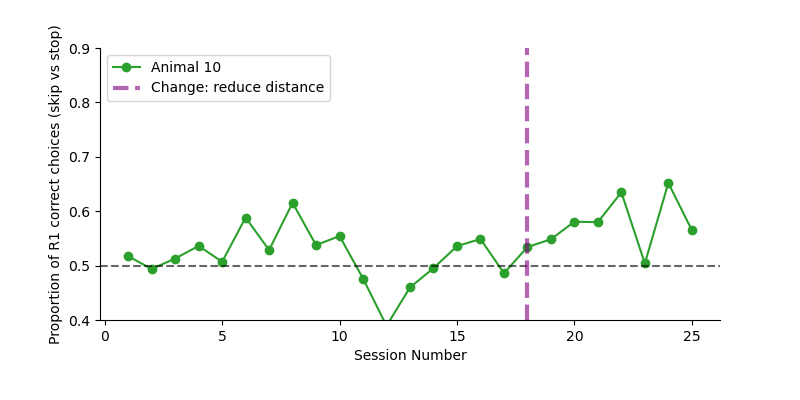

In [50]:
plt.close("all")
plt.figure(figsize=(8, 4))
trialw_beh = analytics.get_analytics('BehaviorTrialwise', session_names=session_names)
display(trialw_beh.columns)

animal_id = 10

animal_data = trialw_beh.loc[1100, animal_id]
aggr_data = []
for i, session_id in enumerate(animal_data.index.unique('session_id')):
    session_trials = animal_data.loc[session_id]
    if (session_trials['flip_Cue1R1_Cue2R2'].iloc[0] == 1) or (session_trials['both_R1_R2_rewarded'].iloc[0] == 1):
        continue
    n = len(session_trials)
    n_R1_correct = session_trials['choice_R2_correct'].sum()
    aggr_data.append((i, float(n_R1_correct/n)))
    
# remove spines
plt.gca().spines['top'].set_visible(False)
plt.subplots_adjust(bottom=0.2)
plt.gca().spines['right'].set_visible(False)
plt.plot([d[0] for d in aggr_data], [d[1] for d in aggr_data], marker='o', label=f'Animal {animal_id}', color='tab:green')
plt.ylim(0.4, 0.9)
plt.xlabel('Session Number')
plt.ylabel('Proportion of R1 correct choices (skip vs stop)')
plt.axhline(0.5, color='k', linestyle='--', alpha=0.6)
plt.axvline(18, linestyle='--', alpha=0.6, label='Change: reduce distance', color='purple', linewidth=3)
plt.legend()
plt.show()
    # display(session_trials)
    # session_mask = trialw_beh.index.get_level_values('session_id') == session_id
    # session_data = trialw_beh[session_mask]
    # print(f"Session {session_id}:")
    # print(session_data[['trial_id', 'cue', 'choice_R1', 'choice_R2', 'trial_outcome']])